In [25]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "data" / "cleaned_listing_raw.csv"
if not DATA_PATH.exists():
    DATA_PATH = BASE_DIR / "cleaned_listing_raw.csv"
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

print("Data path:", DATA_PATH)
print("Model folder:", MODEL_DIR)

Data path: c:\Users\victus\Downloads\AWS final task\ReUse_Campus_ML_Package\reuse_campus_ml\data\cleaned_listing_raw.csv
Model folder: c:\Users\victus\Downloads\AWS final task\ReUse_Campus_ML_Package\reuse_campus_ml\models


In [26]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (3097, 13)
Columns: ['owner_id', 'title', 'description', 'category', 'listing_type', 'condition', 'location', 'status', 'posted_date', 'original_price_inr', 'photos_count', 'views', 'item_age_months_original']


,owner_id,title,description,category,listing_type,condition,location,status,posted_date,original_price_inr,photos_count,views,item_age_months_original
0,U0189,raspberry pi 4 (4gb),"Works fine, visible usage marks. Can hand over...",lab equipment,free,decent,Day Scholar,unlisted,2026-08-28,0.538,0,32.0,7
1,U0658,Mosquito net,Mosquito net. Well maintained. Single bed size...,hostel essentials,free,decent,Hostel B - Block 2,unlisted,2024-12-25,300.000,1,46.0,13
2,U0373,Stapler with pins,Heavy duty. Meet at library. Good starter item...,stationary,lend,new,Hostel E - Block 3,active,14/01/2025,80.000,1,13.0,11
3,U0398,Arduino Uno starter kit,"Arduino Uno starter kit. Brand new, unused. In...",lab equipment,lend,new,Boys Hostel A,available,18 Aug 2024,1380.000,1,3.0,22
4,U0466,Casio fx-991EX ClassWiz calculator,Casio fx-991EX ClassWiz calculator. In good co...,calculator,free,decent,Hostel C - Block 4,unlisted,01/01/2025,1300.000,1,0.0,24


In [27]:
required = {"title", "description", "category"}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

def normalise_category(value):
    value = re.sub(r"\s+", " ", str(value).strip().lower())
    aliases = {
        "hostel essentail": "hostel essentials",
        "hostel essential": "hostel essentials",
        "hostel essentials": "hostel essentials",
        "stationary": "stationery",
        "stationery": "stationery",
        "other": "others",
        "calculators": "calculator",
    }
    return aliases.get(value, value)

model_df = df.copy()
model_df["category_clean"] = model_df["category"].map(normalise_category)
model_df["title_clean"] = model_df["title"].fillna("").astype(str).str.strip()
model_df["description_clean"] = model_df["description"].fillna("").astype(str).str.strip()
model_df["text"] = (model_df["title_clean"] + ". " + model_df["description_clean"]).str.strip()
model_df = model_df[(model_df["text"].str.len() > 2) & (model_df["category_clean"].str.len() > 0)].copy()

print("Rows available for model:", len(model_df))
print("Category counts:")
display(model_df["category_clean"].value_counts())

Rows available for model: 3097
Category counts:


category_clean
hostel essentials    841
others               520
lab equipment        480
books                477
stationery           430
calculator           349
Name: count, dtype: int64

In [28]:
X = model_df["text"]
y = model_df["category_clean"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 2477
Test rows: 620


In [29]:
category_model = Pipeline([
    ("features", FeatureUnion([
        ("word_tfidf", TfidfVectorizer(
            ngram_range=(1, 2), min_df=2, max_features=30000,
            strip_accents="unicode", sublinear_tf=True
        )),
        ("char_tfidf", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 5), min_df=2,
            max_features=30000, sublinear_tf=True
        )),
    ])),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
category_model.fit(X_train, y_train)
y_pred = category_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 0.944

Classification report:
                   precision    recall  f1-score   support

            books       0.97      1.00      0.98        96
       calculator       1.00      0.97      0.99        70
hostel essentials       0.93      0.93      0.93       168
    lab equipment       0.89      0.97      0.93        96
           others       0.94      0.84      0.88       104
       stationery       0.97      0.98      0.97        86

         accuracy                           0.94       620
        macro avg       0.95      0.95      0.95       620
     weighted avg       0.94      0.94      0.94       620



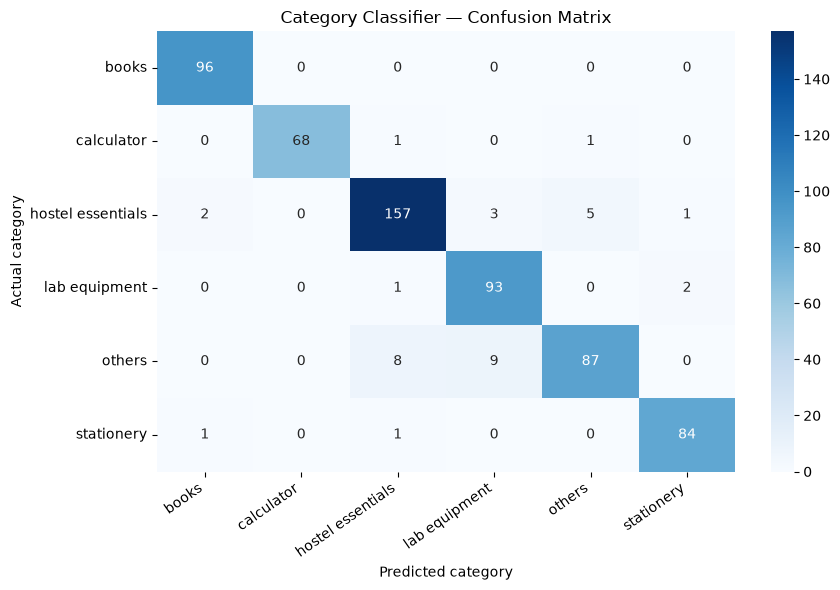

In [30]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Category Classifier — Confusion Matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
def predict_listing_category(title, description=""):
    text = f"{str(title or '').strip()}. {str(description or '').strip()}".strip(" .")
    if len(text) < 2:
        raise ValueError("Enter a title or description.")
    probabilities = category_model.predict_proba([text])[0]
    classes = category_model.classes_
    best_index = int(np.argmax(probabilities))
    return {
        "predicted_category": str(classes[best_index]),
        "confidence": round(float(probabilities[best_index]), 4),
        "needs_review": bool(probabilities[best_index] < 0.55)
    }

predict_listing_category(
    "Casio scientific calculator",
    "Working condition, useful for engineering mathematics."
)

{'predicted_category': 'calculator',
 'confidence': 0.8004,
 'needs_review': False}

In [32]:
joblib.dump(category_model, MODEL_DIR / "category_classifier.joblib")
metrics = {
    "model": "TF-IDF word + character n-grams with Logistic Regression",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "accuracy": float(accuracy),
    "labels": labels,
    "classification_report": classification_report(y_test, y_pred, output_dict=True, zero_division=0),
    "confusion_matrix": cm.tolist(),
    "note": "Random stratified holdout evaluation; validate on real campus data before relying on predictions."
}
(MODEL_DIR / "category_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Saved category model and metrics to:", MODEL_DIR)

Saved category model and metrics to: c:\Users\victus\Downloads\AWS final task\ReUse_Campus_ML_Package\reuse_campus_ml\models


In [33]:
rec = model_df.copy()
rec_cols = [c for c in ["title_clean", "description_clean", "category_clean", "listing_type",
                         "condition", "location", "status", "original_price_inr",
                         "photos_count", "views", "posted_date"] if c in rec.columns]
rec = rec[rec_cols].copy().rename(columns={
    "title_clean": "title", "description_clean": "description", "category_clean": "category"
})
for col in ["title", "description", "category", "listing_type", "condition", "location", "status"]:
    if col in rec:
        rec[col] = rec[col].fillna("").astype(str).str.strip()
rec = rec.reset_index(drop=True)
rec["demo_row_id"] = [f"DEMO-{i:04d}" for i in range(len(rec))]
rec.head()

,title,description,category,listing_type,condition,location,status,original_price_inr,photos_count,views,posted_date,demo_row_id
0,raspberry pi 4 (4gb),"Works fine, visible usage marks. Can hand over...",lab equipment,free,decent,Day Scholar,unlisted,0.538,0,32.0,2026-08-28,DEMO-0000
1,Mosquito net,Mosquito net. Well maintained. Single bed size...,hostel essentials,free,decent,Hostel B - Block 2,unlisted,300.000,1,46.0,2024-12-25,DEMO-0001
2,Stapler with pins,Heavy duty. Meet at library. Good starter item...,stationery,lend,new,Hostel E - Block 3,active,80.000,1,13.0,14/01/2025,DEMO-0002
3,Arduino Uno starter kit,"Arduino Uno starter kit. Brand new, unused. In...",lab equipment,lend,new,Boys Hostel A,available,1380.000,1,3.0,18 Aug 2024,DEMO-0003
4,Casio fx-991EX ClassWiz calculator,Casio fx-991EX ClassWiz calculator. In good co...,calculator,free,decent,Hostel C - Block 4,unlisted,1300.000,1,0.0,01/01/2025,DEMO-0004


In [34]:
def listing_document(row):
    return " ".join([
        str(row.get("title", "")),
        str(row.get("description", "")),
        str(row.get("category", "")),
        str(row.get("listing_type", "")),
        str(row.get("condition", "")),
    ]).strip()

recommendation_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=1, max_features=40000, strip_accents="unicode"
)
recommendation_documents = rec.apply(listing_document, axis=1).tolist()
recommendation_matrix = recommendation_vectorizer.fit_transform(recommendation_documents)
joblib.dump(recommendation_vectorizer, MODEL_DIR / "recommendation_vectorizer.joblib")
rec.to_csv(MODEL_DIR / "recommendation_catalog.csv", index=False)
print("Recommendation catalogue rows:", len(rec))
print("TF-IDF matrix shape:", recommendation_matrix.shape)

Recommendation catalogue rows: 3097
TF-IDF matrix shape: (3097, 5431)


In [35]:
def recommend_items(query="", category=None, listing_type=None, location=None, limit=5):
    candidates = rec.copy()
    if category:
        candidates = candidates[candidates["category"].str.lower() == category.strip().lower()]
    if listing_type:
        candidates = candidates[candidates["listing_type"].str.lower() == listing_type.strip().lower()]
    if location:
        candidates = candidates[candidates["location"].str.lower().str.contains(location.strip().lower(), na=False)]
    if "status" in candidates:
        # Demo only: do not show listings explicitly marked unavailable.
        candidates = candidates[candidates["status"].str.lower().isin(["available", "active", ""]) ]
    if candidates.empty:
        return candidates
    if query.strip():
        q_vec = recommendation_vectorizer.transform([query])
        item_vecs = recommendation_vectorizer.transform(candidates.apply(listing_document, axis=1).tolist())
        scores = cosine_similarity(q_vec, item_vecs).ravel()
    else:
        views = pd.to_numeric(candidates.get("views", 0), errors="coerce").fillna(0)
        scores = views.to_numpy(dtype=float)
    candidates = candidates.copy()
    candidates["similarity_score"] = scores
    return candidates.sort_values("similarity_score", ascending=False).head(limit)[
        [c for c in ["demo_row_id", "title", "category", "listing_type", "condition", "location", "status", "similarity_score"] if c in candidates]
    ]

recommend_items(query="engineering calculator for semester", limit=5)

,demo_row_id,title,category,listing_type,condition,location,status,similarity_score
2953,DEMO-2953,Casio fx-82MS calculator,calculator,lend,like new,"Hostel B, Blk-3",available,0.240725
1045,DEMO-1045,Casio fx-82MS calculator,calculator,lend,new,Hostel B,available,0.233046
159,DEMO-0159,Casio fx-82MS calculator,calculator,lend,decent,Hostel B - Block 3,available,0.228330
1001,DEMO-1001,Casio fx-570MS calculator,calculator,lend,decent,Campus - Library,available,0.202991
145,DEMO-0145,Casio fx-82MS calculator,calculator,lend,decent,Main Gate,available,0.187434


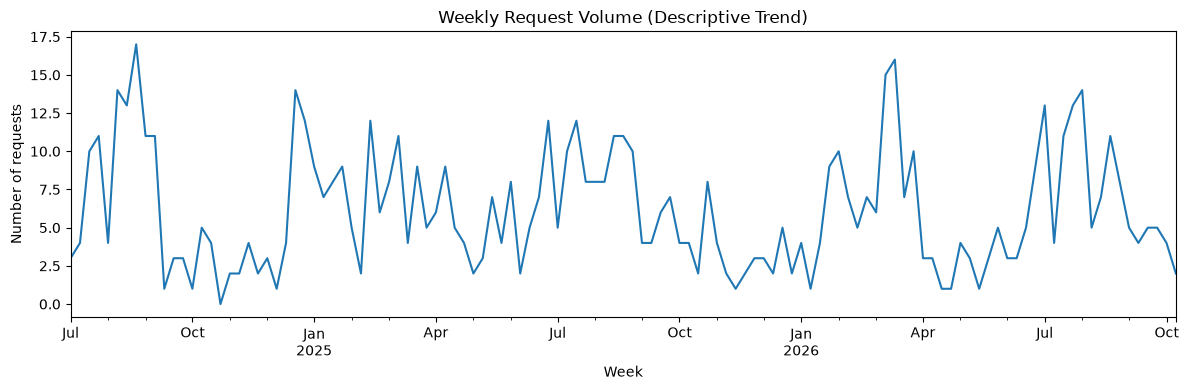

In [36]:
# Requests can support descriptive activity trends. The supplied listings CSV has no listing_id,
# so category-level demand cannot safely be joined to requests using these supplied files.
REQUESTS_PATH = BASE_DIR / "data" / "requests_raw.csv"
if not REQUESTS_PATH.exists():
    REQUESTS_PATH = BASE_DIR / "requests_raw(1).csv"
if REQUESTS_PATH.exists():
    requests_df = pd.read_csv(REQUESTS_PATH)
    if "requested_at" in requests_df.columns:
        requests_df["requested_at_parsed"] = pd.to_datetime(
            requests_df["requested_at"], errors="coerce", dayfirst=True
        )
        daily_requests = (requests_df.dropna(subset=["requested_at_parsed"])
                          .set_index("requested_at_parsed").resample("W").size())
        plt.figure(figsize=(12, 4))
        daily_requests.plot()
        plt.title("Weekly Request Volume (Descriptive Trend)")
        plt.xlabel("Week")
        plt.ylabel("Number of requests")
        plt.tight_layout()
        plt.show()
else:
    print("Optional requests CSV not found. Skipping this section.")